Cell 1

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE_DIR = Path(r"C:\Users\NickK\OneDrive\Υπολογιστής\github\kaggle_store_sales_forecasting")

ADVANCED_DIR = BASE_DIR / "data" / "advanced"

train = pd.read_csv(
    ADVANCED_DIR / "train_advanced.csv"
)

train["date"] = pd.to_datetime(
    train["date"]
)

print(train.shape)

(3000888, 29)


Cell 2

In [2]:
target = "sales"

features = [
    "store_nbr",
    "family",
    "onpromotion",

    "year",
    "month",
    "day",
    "quarter",
    "week",
    "day_of_week",
    "is_weekend",

    "city",
    "state",
    "type",
    "cluster",

    "dcoilwtico",
    "is_payday",
    "is_national_holiday",
    "earthquake_period",

    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28",

    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",

    "rolling_std_7",
    "rolling_std_28"
]

X = train[features]

y = np.log1p(
    train[target]
)

Cell 3

In [3]:
X = pd.get_dummies(
    X,
    drop_first=True
)

print(X.shape)

(3000888, 94)


Cell 4

In [4]:
split_date = "2017-01-01"

train_mask = train["date"] < split_date
valid_mask = train["date"] >= split_date

X_train = X.loc[train_mask]
X_valid = X.loc[valid_mask]

y_train = y.loc[train_mask]

y_valid_original = train.loc[
    valid_mask,
    target
]

print(X_train.shape)
print(X_valid.shape)

(2596374, 94)
(404514, 94)


Cell 5

In [9]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_log_error

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,

    subsample=0.8,
    colsample_bytree=0.8,

    objective="reg:squarederror",

    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

print("Model trained.")

Model trained.


Cell 6

In [10]:
valid_log_preds = xgb_model.predict(
    X_valid
)

valid_preds = np.expm1(
    valid_log_preds
)

valid_preds = np.maximum(
    valid_preds,
    0
)

rmsle = np.sqrt(
    mean_squared_log_error(
        y_valid_original,
        valid_preds
    )
)

print(
    "Validation RMSLE:",
    rmsle
)

Validation RMSLE: 0.45733338164158893


Feature importance

In [11]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": xgb_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values("importance", ascending=False)
)

feature_importance.head(30)

,feature,importance
17,rolling_mean_7,0.622943
14,sales_lag_7,0.128694
18,rolling_mean_14,0.114888
15,sales_lag_14,0.009445
20,rolling_std_7,0.008224
43,"family_LIQUOR,WINE,BEER",0.008199
33,family_GROCERY I,0.008196
39,family_HOME CARE,0.005850
24,family_BEVERAGES,0.005842
28,family_CLEANING,0.005511


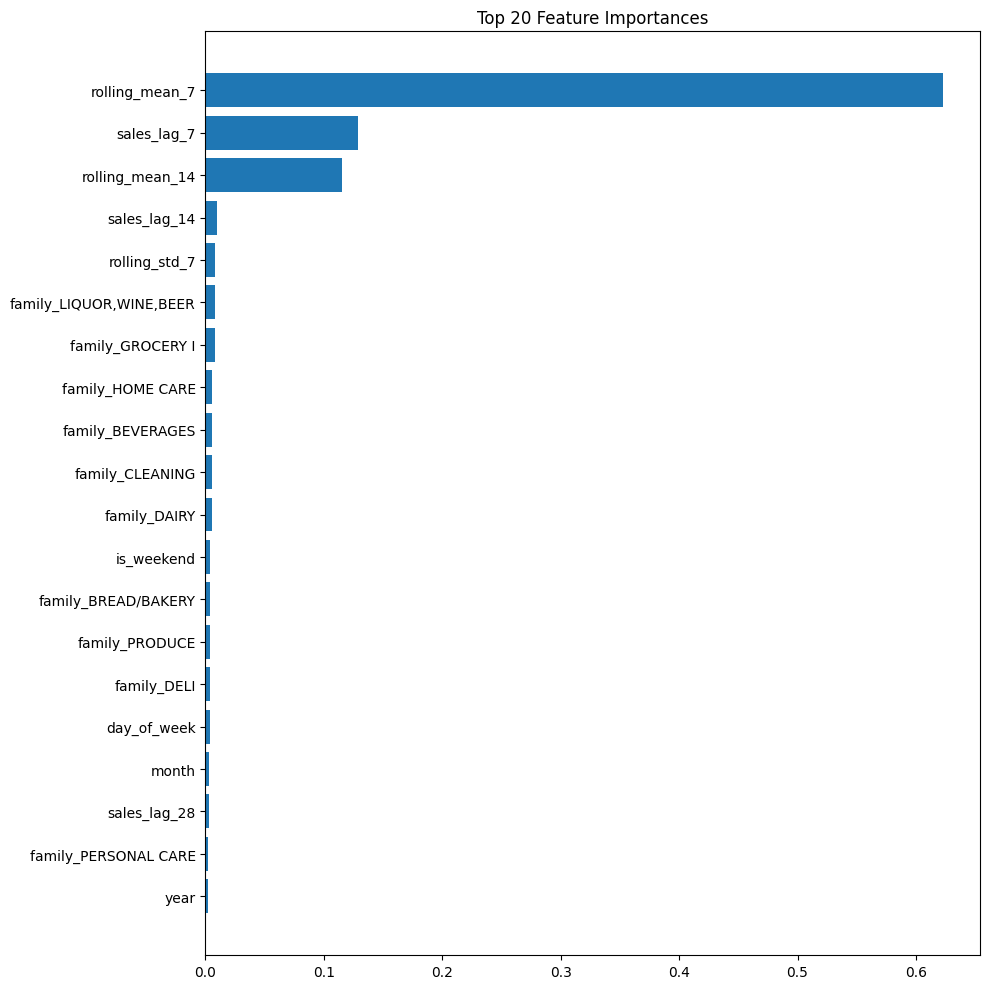

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))

plt.barh(
    feature_importance.head(20)["feature"][::-1],
    feature_importance.head(20)["importance"][::-1]
)

plt.title("Top 20 Feature Importances")
plt.tight_layout()
plt.show()